# 🔭 Uirapuru — Seleção de janelas de calibração (GNSS + Sol no feixe)

Simulação **coarse grained** de 5 dias para verificar quando o **Sol** e os
**satélites GNSS** entram no feixe do radiotelescópio **Uirapuru**
(montagem transit; alt/az conforme `settings.toml`; FWHM≈15°), com vistas à
seleção do melhor momento para **calibração solar**.

### Fluxo
1. Carrega o Uirapuru (observer + feixe) de `settings.toml`
2. Baixa **TLEs frescos** GNSS (GPS/Galileo/GLONASS/BeiDou) via SpaceTrack
3. Calcula **tracks 3D** dos satélites e converte para **alt/az** topocêntrico
4. Calcula o **track do Sol** (efemérides Skyfield)
5. Mede o **offset angular** de cada fonte vs boresight do feixe
   (critério in-beam: offset ≤ FWHM/2 = 7.5° **e** amplitude do padrão > −3 dB)
6. Identifica **janelas candidatas a calibração**: Sol no feixe **sem** GNSS


In [10]:
# ============================================================
# 0. Ambiente e imports
# ============================================================
from __future__ import annotations

import sys
from pathlib import Path

import nest_asyncio
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import astropy.units as u
from astropy.time import Time

# Garante que o src/ está no path
SRC = Path.cwd().resolve().parent / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# ── Núcleo da aplicação ──
from radioskysims.domain.common import Observer, TimeRange
from radioskysims.domain.geometry import SkyfieldGeometryProvider
from radioskysims.domain.tracks.factory import TrackFactory

from radioskysims.infrastructure.beams.loaders.csv import CSVBeamLoader
from radioskysims.infrastructure.config.config_loader import (
    build_radiotelescope_from_settings,
)
from radioskysims.infrastructure.db.engine import Database
from radioskysims.infrastructure.db.satellite.satelliterepository import SatelliteRepository
from radioskysims.infrastructure.external.local_source_track_skyfield_provider import (
    SkyfieldLocalSourceTrackProvider,
)

nest_asyncio.apply()
print("✅ Imports OK")
print(f"RadioSkySim SRC: {SRC}")


✅ Imports OK
RadioSkySim SRC: /media/barosi/RadioSkySim/src


---
## 1. Parâmetros da simulação coarse

- **Janela**: 5 dias (padrão: começa hoje 00:00 UTC; ajuste `START_ISO`).
- **Passo coarse**: 300 s (5 min) → 1441 amostras.
- **Constelações GNSS**: GPS, Galileo, GLONASS, BeiDou.
- **Critério in-beam**: offset angular ≤ FWHM/2 (7.5°) e/ou amplitude do padrão > 50 %.


In [11]:
# ⚙️ Parâmetros da simulação
# ── Janela temporal ──────────────────────────────────────────
# Início UTC (padrão: hoje à 00:00 UTC). Ajuste para outra data, ex.:
#   START_ISO = "2026-09-01T00:00:00"
START_ISO = Time.now().utc.isot[:10] + "T00:00:00"
N_DAYS   = 5                 # duração da janela
STEP_SEC = 300               # passo coarse (300 s = 5 min)

# ── Satélites ────────────────────────────────────────────────
GNSS_CONSTELLATIONS = ["GPS", "GALILEO", "GLONASS", "BEIDOU"]

# ── Critérios "dentro do feixe" ──────────────────────────────
BEAM_FWHM_DEG    = 15.0      # largura do feixe (settings.toml)
INBEAM_HALF_DEG  = BEAM_FWHM_DEG / 2.0   # 7.5°
AMP_DB_THRESHOLD = 0.5       # amplitude normalizada (> −3 dB)
REF_FREQ_MHZ     = 1120.0    # frequência de referência p/ o padrão (banda 1026–1213 MHz)

# ── Constrói o TimeRange de 5 dias (coarse) ──────────────────
t0 = Time(START_ISO, scale="utc")
t1 = t0 + (N_DAYS * 86400.0) * u.s
TIME_RANGE = TimeRange.from_iso(t0.iso, t1.iso, STEP_SEC, unit=u.s)

print(f"Janela: {t0.iso} → {t1.iso} UTC ({N_DAYS} dias)")
print(f"Passo:  {STEP_SEC} s | N amostras: {TIME_RANGE.value.size}")


Janela: 2026-08-26 00:00:00.000 → 2026-08-31 00:00:00.000 UTC (5 dias)
Passo:  300 s | N amostras: 1441


---
## 2. Radiotelescópio Uirapuru + Observador

Carrega o perfil `uirapuru` de `settings.toml` e define o **observador** com a
janela de 5 dias da simulação.


In [12]:
# Carrega o radiotelescópio Uirapuru a partir de settings.toml
rt = build_radiotelescope_from_settings("uirapuru")
ant = rt.antennas[0]
print(f"Telescópio: {rt.name} | Antena: {ant.name}")

# Observador com a janela de 5 dias da simulação
observer = Observer(
    lat=float(rt.observer.lat.to_value("deg")),
    lon=float(rt.observer.lon.to_value("deg")),
    height=float(rt.observer.height.to_value("m")),
    timeframe=TIME_RANGE,
)
print(f"📍 lat={observer.lat.to_value('deg'):.5f}°  lon={observer.lon.to_value('deg'):.5f}°  "
      f"alt={observer.height.to_value('m'):.1f} m")
print(f"🎯 Pointing: mode={ant.pointing.mode}, alt={ant.pointing.alt_deg}°, az={ant.pointing.az_deg}°")
print(f"📡 Faixa: {ant.frequency_range.min_mhz:.1f}–{ant.frequency_range.max_mhz:.1f} MHz | "
      f"FWHM={ant.beam.beam_width_deg}°")
print(f"🌐 Janela: {START_ISO} UTC → +{N_DAYS} d | passo {STEP_SEC} s | "
      f"{TIME_RANGE.value.size} amostras")


Telescópio: UIRAPURU Telescope | Antena: BINGO Horn
📍 lat=-7.21164°  lon=-35.90813°  alt=530.0 m
🎯 Pointing: mode=transit, alt=80.0°, az=0.0°
📡 Faixa: 1026.6–1213.8 MHz | FWHM=15.0°
🌐 Janela: 2026-08-26T00:00:00 UTC → +5 d | passo 300 s | 1441 amostras


---
## 3. TLEs frescos dos satélites GNSS

Baixa **TLEs atualizados** (janela ±5 d em torno da época-alvo) via SpaceTrack
e carrega os satélites de domínio com o TLE **mais próximo** da data-alvo.

> Se o download falhar, o notebook avisa e tenta seguir com os TLEs do banco.


In [13]:
# ── Conecta ao banco e seleciona satélites GNSS ──
db = Database()
repo = SatelliteRepository(engine=db, tr=TIME_RANGE)

epoch_dt = t0.to_datetime()          # época-alvo (início da janela)
gnss = repo.query_constellation(GNSS_CONSTELLATIONS, epoch=epoch_dt)
print(f"🛰️  Satélites GNSS no catálogo: {len(gnss)} "
      f"({', '.join(GNSS_CONSTELLATIONS)})")

# ── Atualiza TLEs via SpaceTrack (janela ±5 d da época-alvo) ──
print("⬇️  Baixando TLEs frescos do SpaceTrack ...")
try:
    repo.update_orbital_elements_sync(
        norad_ids=[s.norad_id for s in gnss],
        epoch=epoch_dt,
    )
    print("✅ TLEs atualizados no banco.")
except Exception as exc:  # noqa: BLE001
    print(f"⚠️  Falha ao atualizar TLEs via SpaceTrack: {exc}")
    print("   Seguindo com os TLEs já existentes no banco (podem ser antigos).")

# ── Carrega domínio com o TLE mais próximo da época-alvo ──
domain_sats = repo.query_constellation(GNSS_CONSTELLATIONS, epoch=epoch_dt)
print(f"✅ Satélites com TLE válido p/ a época-alvo: {len(domain_sats)}")

from collections import Counter
const_counts = Counter(s.constellation for s in domain_sats)
for const, cnt in const_counts.most_common():
    print(f"   {const}: {cnt} satélites")

if not domain_sats:
    raise RuntimeError(
        "Nenhum satélite GNSS com TLE válido para a época-alvo. "
        "Verifique o download do SpaceTrack ou ajuste START_ISO."
    )


{'event': 'spacetrack_update_empty_result', 'requested_count': 148, 'norad_ids': [26407, 27663, 28190, 28474, 28874, 29486, 29601, 32260, 32275, 32276, 32384, 32393, 32395, 32711, 35752, 36111, 36112, 36402, 36585, 36828, 37210, 37256, 37384, 37605, 37763, 37846, 37847, 37867, 37868, 37869, 38091, 38250, 38251, 38775, 38779, 38833, 38857, 38953, 39155, 39166, 39533, 39620, 39741, 40001, 40105, 40128, 40129, 40294, 40315, 40534, 40544, 40545, 40549, 40730, 40748, 40749, 40890, 40938, 41019, 41028, 41174, 41175, 41328, 41330, 41434, 41549, 41550, 41586, 41859, 41860, 41861, 41862, 42939, 43001, 43002, 43055, 43056, 43057, 43058, 43107, 43108, 43207, 43208, 43245, 43246, 43508, 43539, 43564, 43565, 43566, 43567, 43581, 43582, 43602, 43603, 43622, 43623, 43647, 43648, 43683, 43687, 43706, 43707, 43873, 44204, 44231, 44299, 44337, 44506, 44542, 44543, 44709, 44793, 44794, 44850, 44864, 44865, 45344, 45358, 45807, 45854, 46805, 46826, 48859, 49809, 49810, 52984, 54031, 54377, 55268, 56564, 5

🛰️  Satélites GNSS no catálogo: 148 (GPS, GALILEO, GLONASS, BEIDOU)
⬇️  Baixando TLEs frescos do SpaceTrack ...
✅ TLEs atualizados no banco.
✅ Satélites com TLE válido p/ a época-alvo: 148
   BEIDOU: 53 satélites
   GALILEO: 35 satélites
   GPS: 32 satélites
   GLONASS: 28 satélites


---
## 4. Tracks 3D + Geometria topocêntrica

A `TrackFactory` monta as posições 3D (km) de todos os satélites e o
`SkyfieldGeometryProvider` converte para **alt/az** (e theta, range) no
referencial do observador.


In [14]:
# ── Blocos de satélites para a TrackFactory ──
sat_blocks = {
    float(TIME_RANGE.start_jd): {
        "timerange": TIME_RANGE,
        "satellites": domain_sats,
    }
}

# ── Tracks 3D (lazy, Dask) ──
track_factory = TrackFactory()
tracks = track_factory.build(sat_blocks)
print(f"Tracks: {dict(tracks.dataset.sizes)} | {len(tracks.satellite_names)} satélites")

# ── Geometria topocêntrica (alt/az/theta/range) ──
geometry = SkyfieldGeometryProvider(track_factory.skyfield.ts)
geo = geometry.compute(tracks.dataset, observer)
print(f"Geometria: {dict(geo.sizes)} | variáveis: {list(geo.data_vars)}")
print("  (el/az/theta/range em radianos/metros, por satélite × tempo)")


Tracks: {'satellite': 148, 'time': 1441, 'xyz': 3} | 148 satélites
Geometria: {'satellite': 148, 'time': 1441} | variáveis: ['theta', 'range', 'az', 'el', 'ra', 'dec']
  (el/az/theta/range em radianos/metros, por satélite × tempo)


---
## 5. Track do Sol

Usa o `SkyfieldLocalSourceTrackProvider` para calcular a posição aparente do
Sol (alt/az) no referencial do Uirapuru, na mesma grade coarse de 5 dias.


In [15]:
# ── Track do Sol (efemérides Skyfield) ──
sun_provider = SkyfieldLocalSourceTrackProvider()
sun_track = sun_provider.compute_track("Sun", observer, TIME_RANGE)
sun_ds = sun_track.dataset

print(f"Sol: {sun_ds.sizes}")
print(f"  Elevação: {np.degrees(sun_ds['el_rad'].min()):.1f}° .. {np.degrees(sun_ds['el_rad'].max()):.1f}°")
print(f"  Azimute : {np.degrees(sun_ds['az_rad'].min()):.1f}° .. {np.degrees(sun_ds['az_rad'].max()):.1f}°")


Sol: Frozen({'time': 1441})
  Elevação: -88.2° .. 73.9°
  Azimute : 0.0° .. 359.9°


---
## 6. Feixe do Uirapuru e offset angular (in-beam)

Para cada instante, calcula o **offset angular** entre a fonte (Sol/satélite) e o
**boresight** do feixe (alt/az fixos do `settings.toml`, modo transit). Uma
fonte está **in-beam** quando:

- offset ≤ **FWHM/2** (7.5°), **e/ou**
- **amplitude do padrão de radiação** interpolada no offset > −3 dB (50 %).

O padrão é avaliado na frequência de referência (1120 MHz, meio da banda).


In [16]:
# ── Carrega o padrão de radiação ──
beam = CSVBeamLoader(file=ant.beam.beam_pattern_file).load()

# Boresight do feixe (transit, alt/az fixos em graus)
el_b = np.deg2rad(ant.pointing.alt_deg)
az_b = np.deg2rad(ant.pointing.az_deg)

def angular_offset(el_rad, az_rad):
    """Offset angular (rad) entre (el, az) e o boresight do feixe."""
    c = np.sin(el_rad) * np.sin(el_b) + np.cos(el_rad) * np.cos(el_b) * np.cos(az_rad - az_b)
    return np.arccos(np.clip(c, -1.0, 1.0))

# ── Grade do padrão de radiação (0..180°) para interpolação rápida ──
grid_deg = np.linspace(0.0, 180.0, 3601)
amp_grid = np.asarray(
    beam.evaluate(
        frequency=xr.DataArray([REF_FREQ_MHZ], dims="freq", attrs={"units": "MHz"}),
        angle=xr.DataArray(grid_deg, dims="angle"),
        polarization="H_COPOL",
    ).values
).ravel()
amp_grid = np.maximum(np.nan_to_num(amp_grid), 0.0)
if amp_grid.max() > 0:
    amp_grid = amp_grid / amp_grid.max()   # normaliza (máx ≈ 1 no boresight)

# ── Sol: offset + amplitude ──
sun_el = np.asarray(sun_ds["el_rad"].values, dtype=float)
sun_az = np.asarray(sun_ds["az_rad"].values, dtype=float)
sun_off_deg = np.degrees(angular_offset(sun_el, sun_az))
sun_inbeam_off = sun_off_deg <= INBEAM_HALF_DEG
sun_amp = np.interp(sun_off_deg, grid_deg, amp_grid)
sun_inbeam_amp = sun_amp >= AMP_DB_THRESHOLD

# ── Satélites: offset + amplitude (arrays sat × time) ──
sat_el = np.asarray(geo["el"].values, dtype=float)   # (sat, time)
sat_az = np.asarray(geo["az"].values, dtype=float)
sat_off_deg = np.degrees(angular_offset(sat_el, sat_az))
sat_inbeam_off = sat_off_deg <= INBEAM_HALF_DEG
sat_amp = np.interp(sat_off_deg, grid_deg, amp_grid)
sat_inbeam_amp = sat_amp >= AMP_DB_THRESHOLD

n_gnss_off = sat_inbeam_off.sum(axis=0)     # nº GNSS in-beam (offset) por instante
n_gnss_amp = sat_inbeam_amp.sum(axis=0)     # nº GNSS in-beam (amp) por instante

print(f"Feixe: FWHM≈{BEAM_FWHM_DEG}° | in-beam (offset) ≤ {INBEAM_HALF_DEG}° | amp > −3 dB")
print(f"Sol   in-beam: {sun_inbeam_off.sum()} amostras (offset) | "
      f"{sun_inbeam_amp.sum()} (amp)")
print(f"GNSS  in-beam: {n_gnss_off.sum()} amostras-satélite (offset, pico {n_gnss_off.max()}) | "
      f"{n_gnss_amp.sum()} (amp, pico {n_gnss_amp.max()})")


Feixe: FWHM≈15.0° | in-beam (offset) ≤ 7.5° | amp > −3 dB
Sol   in-beam: 23 amostras (offset) | 5 (amp)
GNSS  in-beam: 288 amostras-satélite (offset, pico 2) | 224 (amp, pico 2)


---
## 7. Análise coarse — janelas candidatas a calibração

Agrega tudo num DataFrame por instante e define a janela de calibração ideal:

> **Sol no feixe** (offset ≤ 7.5°) **E nenhum satélite GNSS no feixe** (amp > −3 dB).

Janelas contíguas com ≥ 3 amostras são listadas como candidatas.


In [17]:
# ── DataFrame coarse por instante ──
times_utc = pd.to_datetime(Time(TIME_RANGE.value, format="jd", scale="utc").to_datetime())
df = pd.DataFrame(index=times_utc)
df.index.name = "time_utc"

df["sun_offset_deg"] = sun_off_deg
df["sun_el_deg"]     = np.degrees(sun_el)
df["sun_az_deg"]     = np.degrees(sun_az)
df["sun_inbeam_off"] = sun_inbeam_off
df["sun_inbeam_amp"] = sun_inbeam_amp
df["sun_amp_norm"]   = sun_amp

df["gnss_inbeam_count"]     = n_gnss_off
df["gnss_inbeam_amp_count"] = n_gnss_amp
df["any_gnss_amp"]          = n_gnss_amp > 0

# Janela de calibração: Sol no feixe E nenhum GNSS no feixe (critério amp)
df["calibration_ok"] = df["sun_inbeam_off"] & ~df["any_gnss_amp"]

print("Resumo estatístico:")
print(df[["sun_offset_deg", "sun_el_deg", "gnss_inbeam_count", "gnss_inbeam_amp_count"]]
      .describe().round(2).to_string())
print()
print(f"✅ Amostras com Sol in-beam (offset ≤ {INBEAM_HALF_DEG}°): "
      f"{df['sun_inbeam_off'].sum()} / {len(df)}")
print(f"✅ Amostras de calibração (Sol in-beam e sem GNSS): "
      f"{df['calibration_ok'].sum()} / {len(df)}")


Resumo estatístico:
       sun_offset_deg  sun_el_deg  gnss_inbeam_count  gnss_inbeam_amp_count
count         1441.00     1441.00            1441.00                1441.00
mean            89.09       -2.40               0.20                   0.16
std             49.81       49.40               0.41                   0.36
min              6.07      -88.17               0.00                   0.00
25%             45.25      -45.51               0.00                   0.00
50%             89.57       -1.24               0.00                   0.00
75%            133.47       42.10               0.00                   0.00
max            168.18       73.93               2.00                   2.00

✅ Amostras com Sol in-beam (offset ≤ 7.5°): 23 / 1441
✅ Amostras de calibração (Sol in-beam e sem GNSS): 12 / 1441


In [18]:
# ── Diagnóstico: para onde o feixe aponta e posição do Sol ──
import skyfield.api as sf
from radioskysims.infrastructure.external.skyfield_loader import load_ephemeris

# Boresight (RA/Dec) num instante de referência — transit: DEC fixa, RA varre o céu
t_ref = TIME_RANGE.to_skyfield()[len(TIME_RANGE.value) // 2]
boresight = sf.wgs84.latlon(
    float(observer.lat.to_value("deg")),
    float(observer.lon.to_value("deg")),
    elevation_m=float(observer.height.to_value("m")),
).at(t_ref).from_altaz(alt_degrees=ant.pointing.alt_deg, az_degrees=ant.pointing.az_deg)
ra_b, dec_b, _ = boresight.radec()
dec_beam_deg = float(np.degrees(dec_b.radians))
ra_beam_deg = float(ra_b.hours * 15.0)
print(f"🎯 Boresight (instante ref.): RA≈{ra_beam_deg:6.1f}°  |  DEC≈{dec_beam_deg:+.1f}°")

# Posição do Sol em RA/Dec (grade coarse)
eph = load_ephemeris()
obs_geo = sf.wgs84.latlon(
    float(observer.lat.to_value("deg")),
    float(observer.lon.to_value("deg")),
    elevation_m=float(observer.height.to_value("m")),
)
app = (eph["earth"] + obs_geo).at(TIME_RANGE.to_skyfield()).observe(eph["sun"]).apparent()
ra_sun_h, dec_sun, _ = app.radec()
print(f"☀️  Sol: DEC≈{np.degrees(np.asarray(dec_sun.radians)).min():+.1f}°.."
      f"{np.degrees(np.asarray(dec_sun.radians)).max():+.1f}°")

# ── Aproximação máxima do Sol ao feixe, por dia ──
rows = []
for day, sub in df.groupby(df.index.normalize()):
    i = sub["sun_offset_deg"].idxmin()
    rows.append({
        "dia": str(day.date()),
        "hora_utc": str(i.time())[:5],
        "offset_min_deg": round(float(sub["sun_offset_deg"].min()), 1),
        "sol_el_deg": round(float(sub.loc[i, "sun_el_deg"]), 1),
        "sol_az_deg": round(float(sub.loc[i, "sun_az_deg"]), 1),
        "gnss_max": int(sub["gnss_inbeam_amp_count"].max()),
    })
daily_approach = pd.DataFrame(rows)
print("\nAproximação máxima do Sol ao boresight por dia:")
print(daily_approach.to_string(index=False))
print("\n→ Se o offset mínimo diário for > FWHM/2, o Sol NÃO cruza o feixe principal.")


🎯 Boresight (instante ref.): RA≈ 120.5°  |  DEC≈+2.9°
☀️  Sol: DEC≈+8.8°..+10.6°

Aproximação máxima do Sol ao boresight por dia:
       dia hora_utc  offset_min_deg  sol_el_deg  sol_az_deg  gnss_max
2026-08-26    14:25             7.5        72.5         0.4         1
2026-08-27    14:25             7.1        72.9         0.1         1
2026-08-28    14:25             6.8        73.2       359.9         1
2026-08-29    14:25             6.4        73.6       359.6         2
2026-08-30    14:25             6.1        73.9       359.3         1
2026-08-31    00:00           142.3       -54.3       274.9         0

→ Se o offset mínimo diário for > FWHM/2, o Sol NÃO cruza o feixe principal.


In [19]:
# ── Janelas candidatas (agrupamento por contiguidade) ──
def contiguous_runs(mask, idx, min_len=1):
    """Retorna [(t_início, t_fim, nº amostras)] para trechos True contíguos."""
    runs, start = [], None
    n = len(mask)
    for i in range(n + 1):
        flag = mask[i] if i < n else False
        if flag and start is None:
            start = i
        elif not flag and start is not None:
            if (i - start) >= min_len:
                runs.append((idx[start], idx[i - 1], i - start))
            start = None
    return runs

runs = contiguous_runs(df["calibration_ok"].values, df.index, min_len=3)
print(f"{'Início (UTC)':<22}{'Fim (UTC)':<22}{'Dur. (min)':>10}  "
      f"{'Sol off min':>12}  {'GNSS máx':>9}")
print("-" * 80)
for t0r, t1r, n in runs:
    sun_off_min = df.loc[t0r:t1r, "sun_offset_deg"].min()
    gnss_max = df.loc[t0r:t1r, "gnss_inbeam_amp_count"].max()
    dur_min = n * (STEP_SEC / 60)
    print(f"{str(t0r):<22}{str(t1r):<22}{dur_min:>10.0f}  "
          f"{sun_off_min:>11.1f}°  {gnss_max:>9d}")

if not runs:
    print("⚠️  Nenhuma janela contígua de calibração com o critério atual.")


Início (UTC)          Fim (UTC)             Dur. (min)   Sol off min   GNSS máx
--------------------------------------------------------------------------------
2026-08-27 14:19:59.9999822026-08-27 14:29:59.999987        15          7.1°          0
2026-08-28 14:15:00   2026-08-28 14:35:00.000009        25          6.8°          0


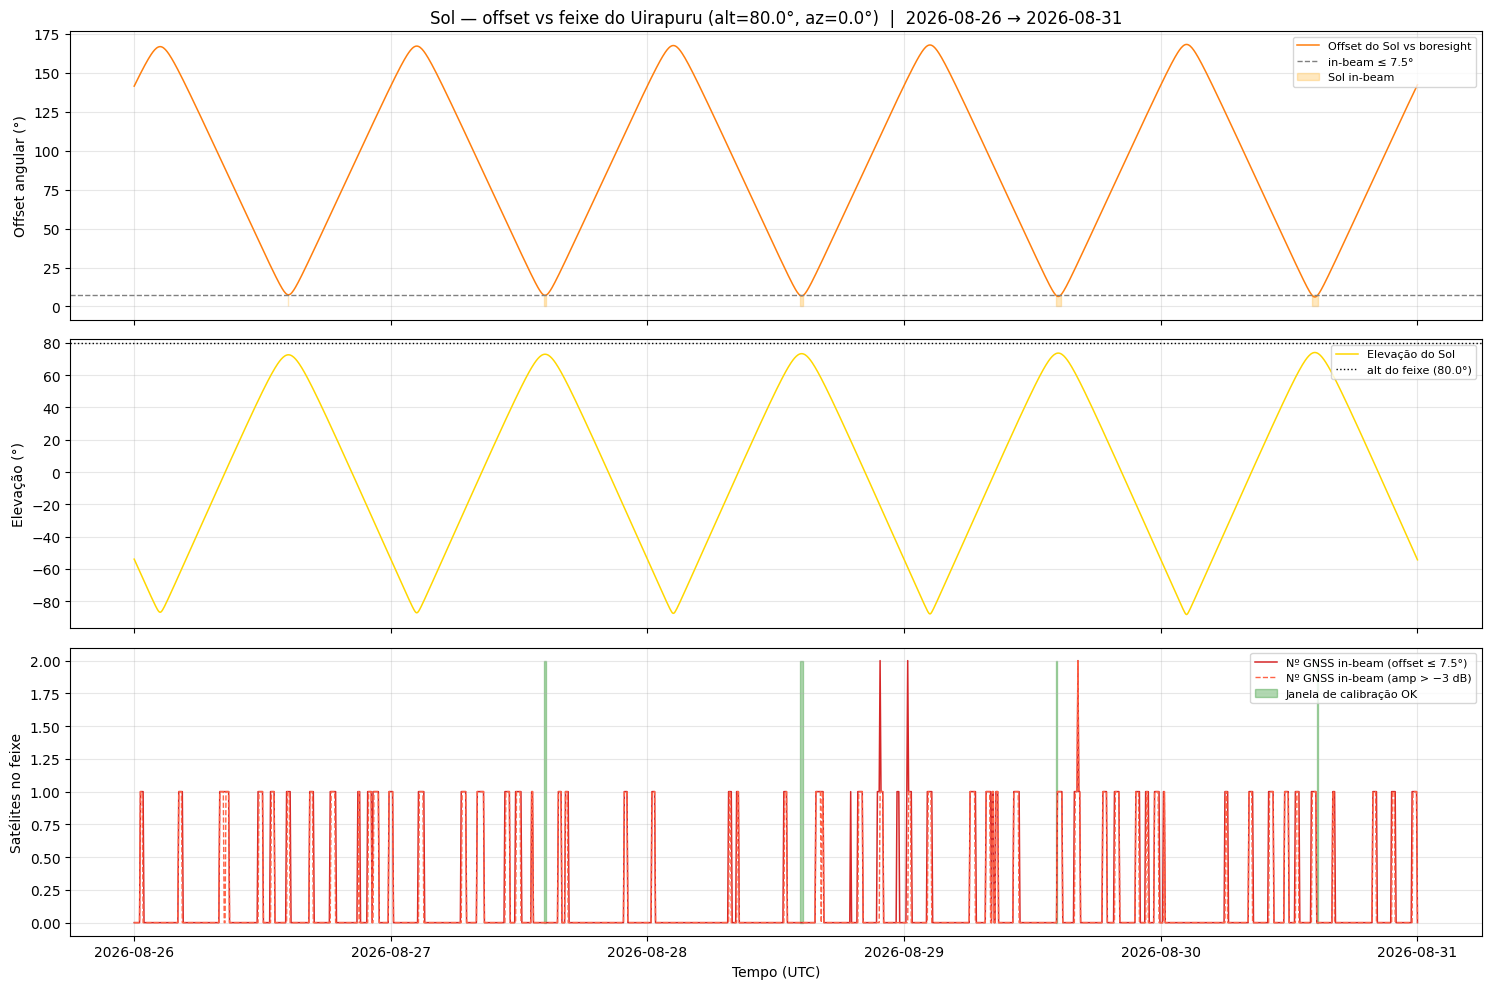

In [20]:
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

# (a) Offset do Sol vs boresight
ax = axes[0]
ax.plot(df.index, df["sun_offset_deg"], color="tab:orange", lw=1.1,
        label="Offset do Sol vs boresight")
ax.axhline(INBEAM_HALF_DEG, color="gray", ls="--", lw=1,
           label=f"in-beam ≤ {INBEAM_HALF_DEG}°")
ax.fill_between(df.index, 0, INBEAM_HALF_DEG,
                where=df["sun_inbeam_off"], color="orange", alpha=0.25,
                label="Sol in-beam")
ax.set_ylabel("Offset angular (°)")
ax.set_title(f"Sol — offset vs feixe do Uirapuru (alt={ant.pointing.alt_deg}°, "
             f"az={ant.pointing.az_deg}°)  |  {df.index[0]:%Y-%m-%d} → {df.index[-1]:%Y-%m-%d}")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)

# (b) Elevação do Sol
ax = axes[1]
ax.plot(df.index, df["sun_el_deg"], color="gold", lw=1.1, label="Elevação do Sol")
ax.axhline(ant.pointing.alt_deg, color="black", ls=":", lw=1,
           label=f"alt do feixe ({ant.pointing.alt_deg}°)")
ax.set_ylabel("Elevação (°)")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)

# (c) GNSS in-beam + janelas de calibração
ax = axes[2]
ax.plot(df.index, df["gnss_inbeam_count"], color="tab:red", lw=1.1,
        label="Nº GNSS in-beam (offset ≤ 7.5°)")
ax.plot(df.index, df["gnss_inbeam_amp_count"], color="tomato", lw=1.0, ls="--",
        label="Nº GNSS in-beam (amp > −3 dB)")
ax.fill_between(df.index, 0, df["gnss_inbeam_count"].max(),
                where=df["calibration_ok"], color="green", alpha=0.3,
                label="Janela de calibração OK")
ax.set_xlabel("Tempo (UTC)")
ax.set_ylabel("Satélites no feixe")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 8.2 Detalhe diário (trânsito do Sol × GNSS)


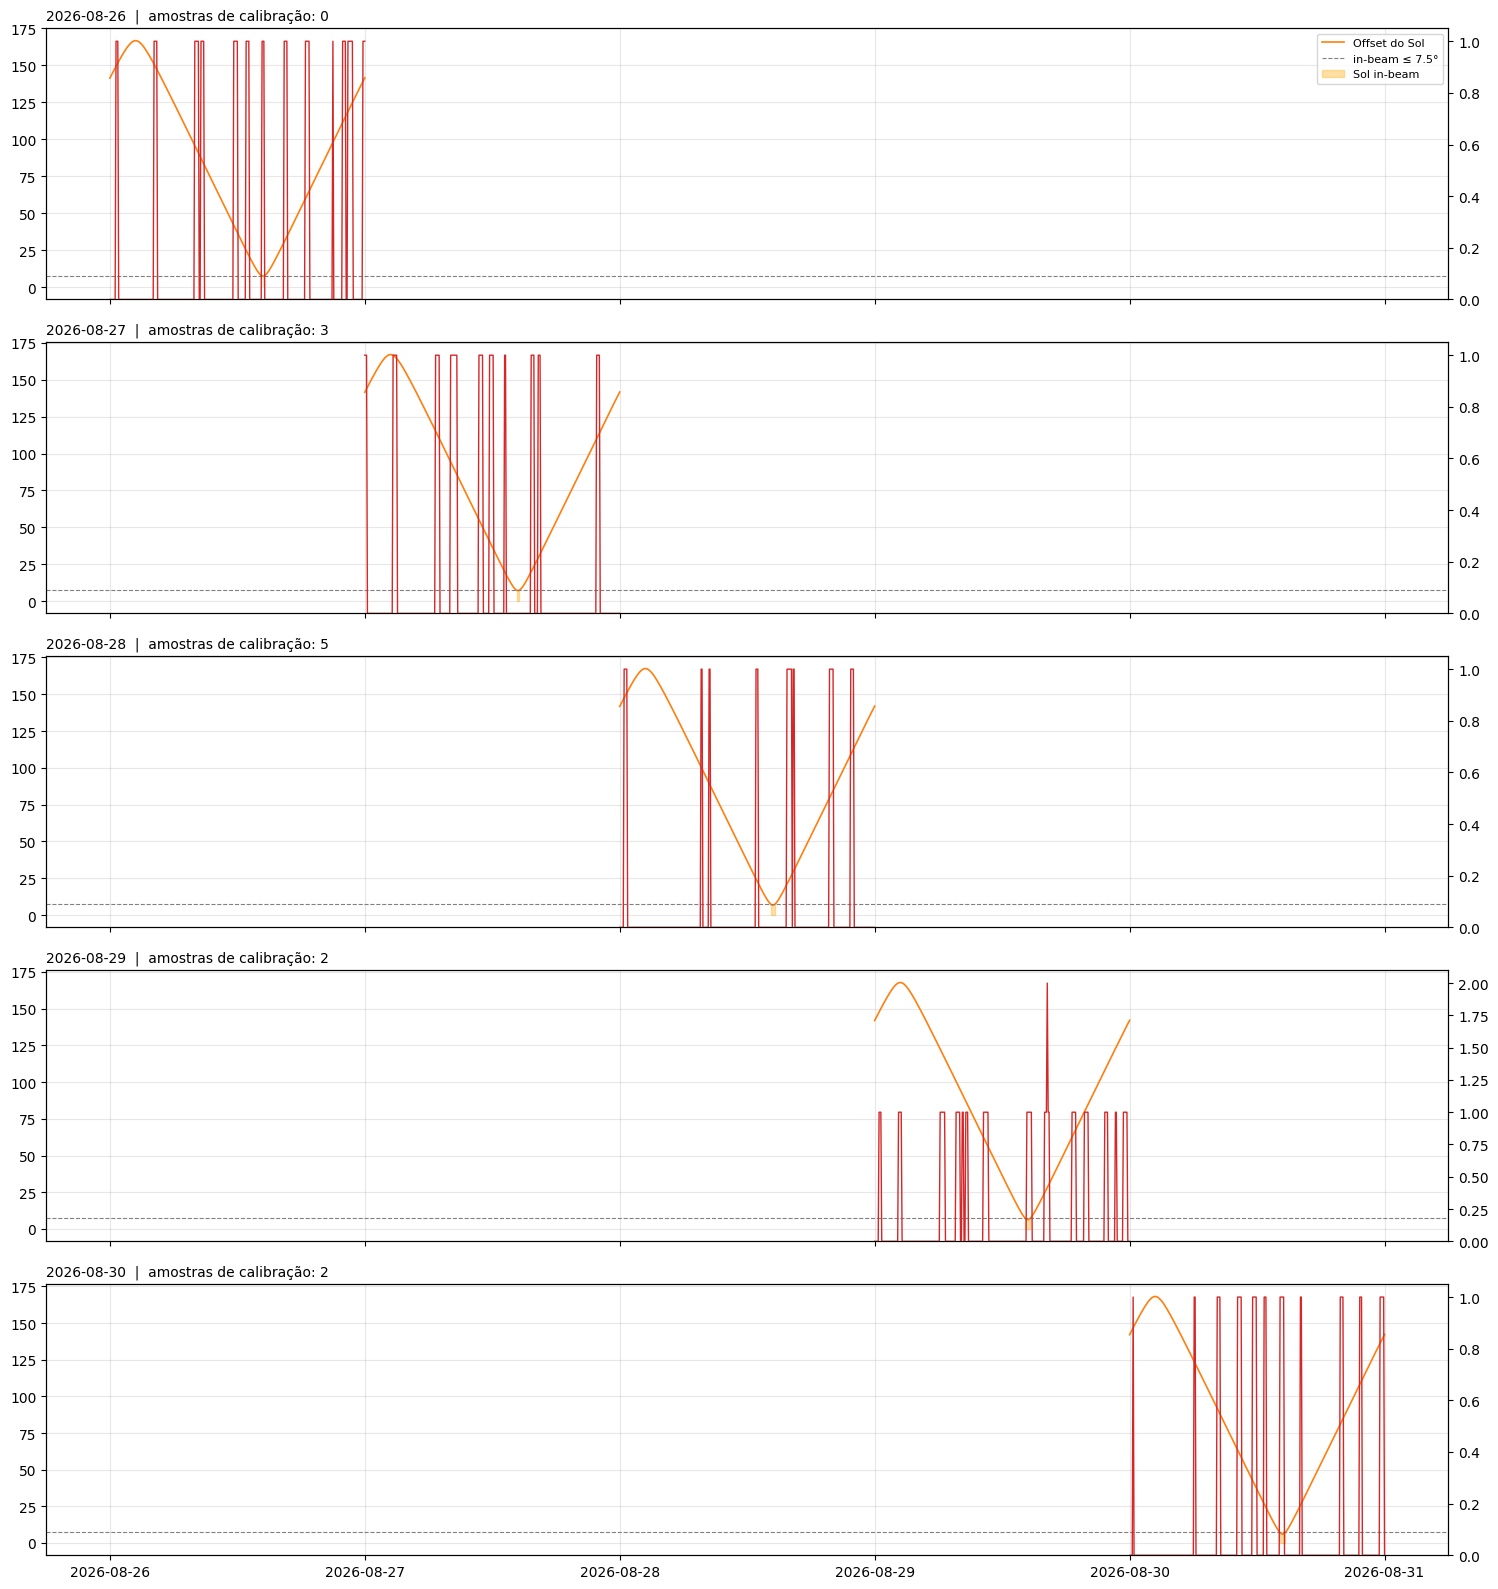

In [21]:
days = pd.date_range(df.index[0].normalize(), periods=N_DAYS, freq="D")
fig, axes = plt.subplots(N_DAYS, 1, figsize=(15, 3.2 * N_DAYS), sharex=True)

for ax, day in zip(axes, days, strict=False):
    d0, d1 = day, day + pd.Timedelta(days=1)
    sub = df.loc[d0:d1]

    ax.plot(sub.index, sub["sun_offset_deg"], color="tab:orange", lw=1.2,
            label="Offset do Sol")
    ax.axhline(INBEAM_HALF_DEG, color="gray", ls="--", lw=0.8,
               label=f"in-beam ≤ {INBEAM_HALF_DEG}°")
    ax.fill_between(sub.index, 0, INBEAM_HALF_DEG,
                    where=sub["sun_inbeam_off"], color="orange", alpha=0.35,
                    label="Sol in-beam")

    ax2 = ax.twinx()
    ax2.plot(sub.index, sub["gnss_inbeam_amp_count"], color="tab:red", lw=1.0,
             label="GNSS in-beam (amp)")
    ax2.set_ylim(bottom=0)

    n_ok = int(sub["calibration_ok"].sum())
    ax.set_title(f"{day:%Y-%m-%d}  |  amostras de calibração: {n_ok}", loc="left", fontsize=10)
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


### 8.3 Exportar resumo (opcional)

Salva o DataFrame coarse e a lista de janelas candidatas para reuso/análise
posterior (diretório `data/aux/`).


In [23]:
# ── Exporta resumo (raiz do projeto: data/aux/) ──
out_dir = SRC.parent / "data" / "aux"
out_dir.mkdir(parents=True, exist_ok=True)

# Série temporal coarse
csv_series = out_dir / f"uirapuru_calibration_coarse_{START_ISO[:10]}.csv"
df.to_csv(csv_series)
print(f"💾 Série coarse salva: {csv_series}")

# Janelas candidatas
if runs:
    rows = []
    for t0r, t1r, n in runs:
        rows.append({
            "inicio_utc": str(t0r),
            "fim_utc": str(t1r),
            "duracao_min": n * (STEP_SEC / 60),
            "n_amostras": n,
            "sol_offset_min_deg": float(df.loc[t0r:t1r, "sun_offset_deg"].min()),
            "gnss_max": int(df.loc[t0r:t1r, "gnss_inbeam_amp_count"].max()),
        })
    csv_runs = out_dir / f"uirapuru_calibration_windows_{START_ISO[:10]}.csv"
    pd.DataFrame(rows).to_csv(csv_runs, index=False)
    print(f"💾 Janelas salvas: {csv_runs}")
else:
    print("⚠️  Sem janelas candidatas para exportar.")


💾 Série coarse salva: /media/barosi/RadioSkySim/data/aux/uirapuru_calibration_coarse_2026-08-26.csv
💾 Janelas salvas: /media/barosi/RadioSkySim/data/aux/uirapuru_calibration_windows_2026-08-26.csv
